# Linear SVM and garment error analysis

Reproduces the UJ474 Phase 1 SVM experiment, exports the two standardized records, and creates focused garment-error figures.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from aml.data import get_train_val_test_splits
from aml.features import get_features
from aml.models.svm import tune_svm, evaluate_final_svm, make_result_record, save_result
from aml.error_analysis import (plot_confusion_matrix, plot_garment_confusion_submatrix, extract_misclassifications, plot_misclassification_gallery)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS = ROOT / 'reports' / 'results'
FIGURES = ROOT / 'reports' / 'figures' / 'errors'
splits = get_train_val_test_splits(data_dir=ROOT / 'data' / 'raw')
FIGURES.mkdir(parents=True, exist_ok=True)
splits['class_names']

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [2]:
all_runs = {}
for representation in ('pixels', 'hog'):
    X_train = get_features(splits['X_train'], representation)
    X_val = get_features(splits['X_val'], representation)
    X_train_full = get_features(splits['X_train_full'], representation)
    X_test = get_features(splits['X_test'], representation)
    best_C, tuning = tune_svm(X_train, splits['y_train'], X_val, splits['y_val'])
    model, metrics, latency_ms, parameter_count = evaluate_final_svm(X_train_full, splits['y_train_full'], X_test, splits['y_test'], best_C)
    record = make_result_record(representation, best_C, tuning, metrics, latency_ms, parameter_count, len(X_train), len(X_val), len(X_test))
    save_result(record, RESULTS)
    all_runs[representation] = {'model': model, 'metrics': metrics, 'tuning': tuning, 'record': record, 'predictions': model.predict(X_test)}
    display(pd.DataFrame(tuning))
    print(json.dumps(record, indent=2))

Fitting Linear SVM with C=0.1...


Fitting Linear SVM with C=1.0...


Fitting Linear SVM with C=10.0...


,C,val_accuracy,val_macro_f1,n_iter,fit_seconds
0,0.1,0.857167,0.855650,156,75.726471
1,1.0,0.855083,0.853585,648,156.394654
2,10.0,0.855583,0.854083,547,171.825706


{
  "model": "svm",
  "features": "pixels",
  "best_params": {
    "C": 0.1,
    "max_iter": 2000
  },
  "train_n": 48000,
  "val_n": 12000,
  "test_n": 10000,
  "validation_accuracy": 0.8571666666666666,
  "validation_macro_f1": 0.855650305488567,
  "test_accuracy": 0.838,
  "test_macro_f1": 0.8356606903537422,
  "per_class_recall": [
    0.819,
    0.954,
    0.728,
    0.864,
    0.777,
    0.916,
    0.507,
    0.934,
    0.94,
    0.941
  ],
  "parameter_count": 7850,
  "inference_latency_ms_per_image": 0.0013253330253064632,
  "test_confusion_matrix": [
    [
      819,
      3,
      15,
      52,
      8,
      2,
      89,
      0,
      12,
      0
    ],
    [
      3,
      954,
      5,
      27,
      5,
      0,
      3,
      1,
      2,
      0
    ],
    [
      25,
      4,
      728,
      14,
      140,
      0,
      77,
      0,
      12,
      0
    ],
    [
      27,
      19,
      18,
      864,
      33,
      0,
      32,
      1,
      6,
      0
    ],
  

Fitting Linear SVM with C=0.1...


Fitting Linear SVM with C=1.0...


Fitting Linear SVM with C=10.0...


,C,val_accuracy,val_macro_f1,n_iter,fit_seconds
0,0.1,0.852250,0.851210,23,26.324552
1,1.0,0.853083,0.852083,27,31.823030
2,10.0,0.852833,0.851791,26,32.132878


{
  "model": "svm",
  "features": "hog",
  "best_params": {
    "C": 1.0,
    "max_iter": 2000
  },
  "train_n": 48000,
  "val_n": 12000,
  "test_n": 10000,
  "validation_accuracy": 0.8530833333333333,
  "validation_macro_f1": 0.8520825647187877,
  "test_accuracy": 0.8423,
  "test_macro_f1": 0.8406486287926717,
  "per_class_recall": [
    0.8,
    0.948,
    0.734,
    0.864,
    0.738,
    0.931,
    0.546,
    0.939,
    0.971,
    0.952
  ],
  "parameter_count": 3250,
  "inference_latency_ms_per_image": 0.0005978340050205588,
  "test_confusion_matrix": [
    [
      800,
      9,
      31,
      54,
      6,
      3,
      88,
      0,
      9,
      0
    ],
    [
      1,
      948,
      2,
      41,
      2,
      0,
      5,
      0,
      1,
      0
    ],
    [
      16,
      2,
      734,
      11,
      142,
      0,
      89,
      0,
      6,
      0
    ],
    [
      20,
      24,
      13,
      864,
      36,
      0,
      37,
      0,
      4,
      2
    ],
    [


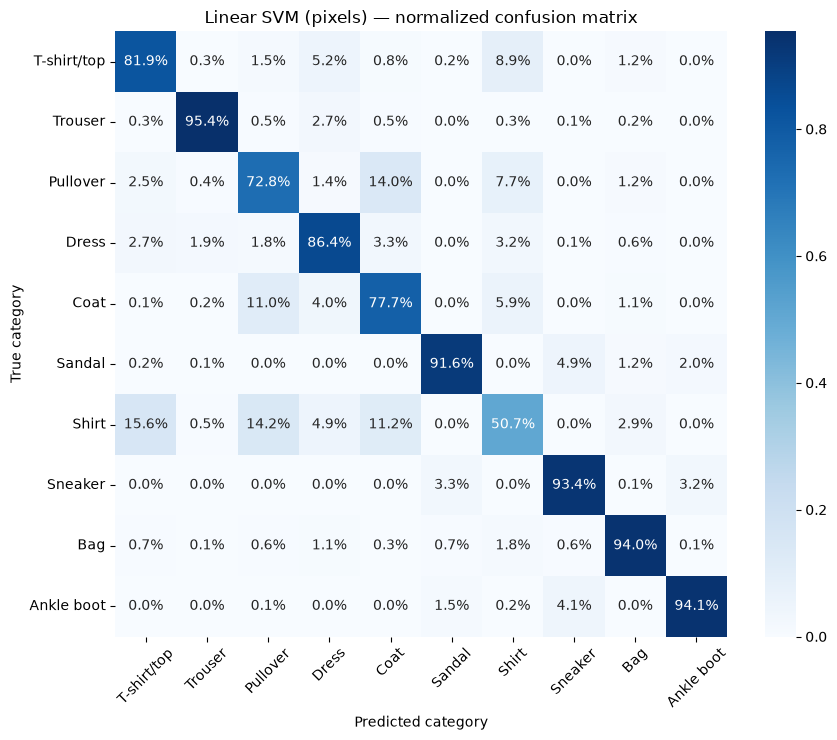

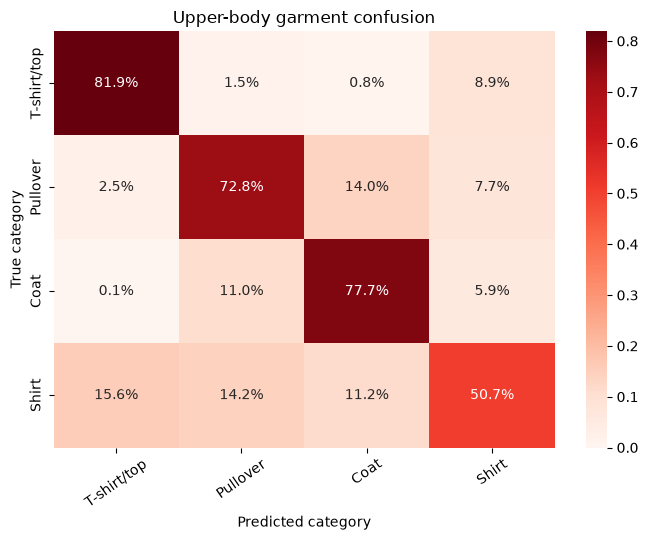

Gallery representation: pixels


In [3]:
best_representation = max(all_runs, key=lambda name: all_runs[name]['record']['validation_macro_f1'])
run = all_runs[best_representation]
cm = run['metrics']['confusion_matrix']
plot_confusion_matrix(cm, splits['class_names'], f'Linear SVM ({best_representation}) — normalized confusion matrix', FIGURES / f'svm_{best_representation}_confusion_matrix.png')
plot_garment_confusion_submatrix(cm, splits['class_names'], save_path=FIGURES / f'svm_{best_representation}_upper_body_confusion.png')
plt.show()
print('Gallery representation:', best_representation)

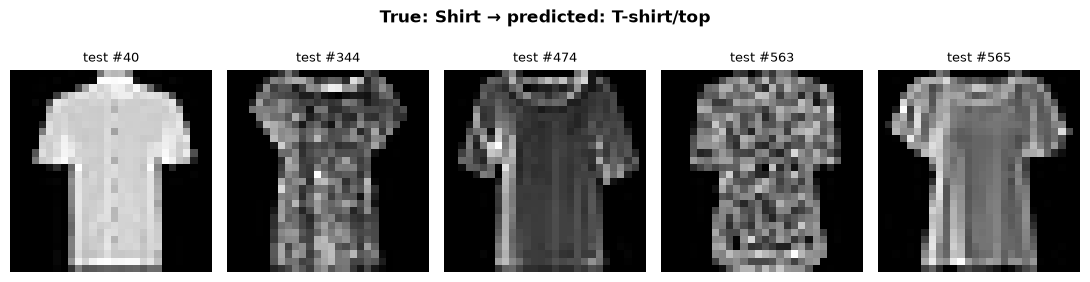

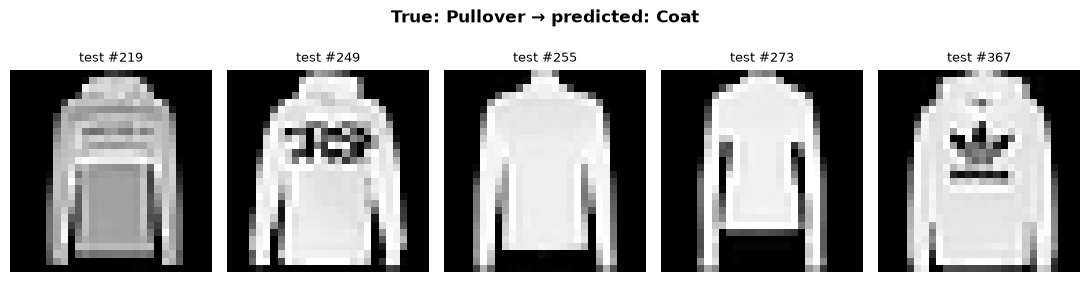

In [4]:
for true_class, predicted_class in [(6, 0), (2, 4)]:
    images, indices = extract_misclassifications(splits['y_test'], run['predictions'], splits['X_test'], true_class, predicted_class)
    plot_misclassification_gallery(images, indices, splits['class_names'][true_class], splits['class_names'][predicted_class], FIGURES / f'svm_{best_representation}_{true_class}_as_{predicted_class}_gallery.png')
    plt.show()

## Interpretation

Read `reports/error_analysis.md` alongside the saved figures. The SVM's margin can only separate the information contained in pixels or fixed HOG bins; it cannot learn the missing spatial hierarchy needed for subtle collar, sleeve, and texture differences. A Phase 2 CNN should use the same test split and compare the Shirt row of its confusion matrix directly with this baseline.